# Part 3 – Joining model

**Question.** How does the chance that a non-member joins depend on the price they are offered? This model gives the tool its joining curve, $j(p)$.

**Findings** (details and checks below):

* **Joining depends on price and on ad exposure together.** At \$12, 0.5% of prospects with no podcast or social exposure that season join, against 71% of those with heavy exposure of both. Price sets how much exposure it takes.
* **Each \$1 lower price raises the log-odds of joining by 0.90 at \$12**, holding exposure fixed. The response is steeper at high prices (1.21 at \$15) and flatter at low ones (0.40 at \$7).
* **The slope comes from randomized discount depths only**, and exposure is the same at every depth, so price does not change it.
* **The price response is the same in every season once exposure is in the model** (−0.86 to −1.02 at \$12). Without it the slope ranges from −0.18 to −0.91, and season effects are needed to fit the level.
* **The price response carries over to the cut.** Trained on pre-cut seasons alone and given post-cut exposure, the model predicts post-cut joining by price within 0.8 pp at \$10–\$12 and 1.2 pp at \$7–\$9, prices it never saw.
* **Limitation: the model does not forecast a season's level.** That depends on how much advertising prospects see, which is not known in advance. The tool takes the ad environment as a stated scenario (a past season to resemble).

---

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

import utils as u

u.apply_style()
CUT = u.CUT_T                                        # spring 2019
BLUE, ORANGE = '#2a78d6', '#eb6834'

panel = u.load_panel(
    'data/customer_panel.csv',
    extra_cols=('customer_id', 'discount_flag', 'social_ad_impressions', 'podcast_ad_listen'))


def fit_logit(formula, data):
    """Logit with standard errors clustered by customer."""
    return smf.logit(formula, data).fit(disp=0, cov_type='cluster', cov_kwds={'groups': data['customer_id']})

## 1. Sample

* **Unit.** One row per customer and season, for customers in the five cut regions who were **not members the season before**. `joined` = 1 if they are a member this season.
* **Why the cut regions only.** Panem has no offers. Its only price variation is the base price compared with the cut regions, a comparison that rests on one control region. Within the cut regions, the price slope is estimated from the randomized depths.
* **Exposure.** `pod` is the customer's podcast ad listens this season and `soc` their social ad impressions.
* **Returning ex-members** are kept, so people who cancel can rejoin.

In [2]:
df = panel.sort_values(['customer_id', 't']).reset_index(drop=True)
df['prev_member'] = df.groupby('customer_id')['sign_up_flag'].shift(1)

keep = df['region_name'].ne(u.CONTROL) & df['t'].ge(3) & df['prev_member'].eq(0)
d = (df[keep].rename(columns={'sign_up_flag': 'joined', 'membership_price': 'price', 'discount_flag': 'offer',
                              'podcast_ad_listen': 'pod', 'social_ad_impressions': 'soc'})
             .reset_index(drop=True))
d['post'] = d['t'].ge(CUT).astype(int)
d['depth'] = np.where(d['offer'].eq(1), np.where(d['post'].eq(1), 12, 15) - d['price'], 0)      # $ off the base price
del panel, df


def add_terms(x):
    """Price and exposure terms of the joining model. Used for the data and for tool scenarios."""
    x = x.copy()
    x['price_sq'] = (x['price'] - 12) ** 2
    x['pod_soc'] = x['pod'] * x['soc']
    x['sqrt_pod_soc'] = np.sqrt(x['pod_soc'])
    x['pod_zero'] = x['pod'].eq(0).astype(int)
    x['soc_zero'] = x['soc'].eq(0).astype(int)
    return x


d = add_terms(d)
print(f"{len(d):,} rows, {d['customer_id'].nunique():,} customers, joining rate {d['joined'].mean():.1%}, "
      f"{d['offer'].mean():.0%} offered")

# Check the price menu: offered = base - $1...$5; not offered = base ($15, then $12 from spring 2019)
d.groupby(['post', 'offer', 'price'])['joined'].agg(rows='size', join_rate='mean').reset_index().round(4)

2,669,723 rows, 349,623 customers, joining rate 6.3%, 25% offered


,post,offer,price,rows,join_rate
0,0,0,15,1399080,0.0366
1,0,1,10,93398,0.1667
2,0,1,11,93046,0.1312
3,0,1,12,94109,0.0975
4,0,1,13,93666,0.0729
5,0,1,14,93232,0.0529
6,1,0,12,602384,0.0598
7,1,1,7,40036,0.2522
8,1,1,8,40376,0.2042
9,1,1,9,40308,0.1572


## 2. Why ad exposure belongs in the model

In [3]:
# 2.1 Joining rate (%) by price and this season's ad exposure
BANDS = [-1, 0, 25, 80, 200, np.inf]
BAND_LABELS = ['none', '1-25', '26-80', '81-200', 'over 200']
d['exposure_band'] = pd.cut(d['pod_soc'], BANDS, labels=BAND_LABELS)
by_band = (100 * d.pivot_table(index='exposure_band', columns='price', values='joined', observed=True)).round(1)
by_band.insert(0, '% of prospects', (100 * d['exposure_band'].value_counts(normalize=True)).round(1))
by_band.rename_axis('listens x impressions')

price,% of prospects,7,8,9,10,11,12,13,14,15
listens x impressions,,,,,,,,,,
none,70.6,14.3,9.8,5.8,3.1,1.3,0.5,0.1,0.0,0.0
1-25,10.0,35.5,27.7,20.1,12.1,6.5,2.6,0.9,0.2,0.0
26-80,10.9,65.3,58.5,48.3,37.9,25.6,14.6,6.7,2.6,0.5
81-200,6.8,96.6,95.6,92.5,88.3,81.7,70.7,57.6,39.9,22.8
over 200,1.6,100.0,100.0,100.0,100.0,100.0,100.0,99.8,98.8,95.9


In [4]:
# 2.2 Is exposure affected by price? Compare it across the randomized depths, and offered vs not offered
balance = d.groupby(['post', 'offer', 'depth']).agg(rows=('joined', 'size'), listens=('pod', 'mean'),
                                                    impressions=('soc', 'mean'),
                                                    any_exposure=('pod_soc', lambda s: s.gt(0).mean()))
offered = balance.xs(1, level='offer')
spread = offered.groupby('post')[['listens', 'impressions']].agg(lambda s: s.max() - s.min())
print(f"Across the five depths, average listens differ by at most {spread['listens'].max():.2f} "
      f"and impressions by at most {spread['impressions'].max():.2f}")
balance.round(3)

Across the five depths, average listens differ by at most 0.08 and impressions by at most 0.05


rows  listens  impressions  any_exposure
post offer depth                                             
0    0     0      1399080    4.752        4.728         0.319
     1     1        93232    4.739        4.726         0.320
           2        93666    4.704        4.720         0.318
           3        94109    4.756        4.721         0.318
           4        93046    4.772        4.724         0.322
           5        93398    4.721        4.742         0.318
1    0     0       602384    3.027        4.463         0.236
     1     1        39911    3.080        4.488         0.239
           2        40177    3.099        4.479         0.241
           3        40308    3.023        4.505         0.238
           4        40376    3.060        4.479         0.236
           5        40036    3.035        4.453         0.236

**Reading**

* **Exposure moves joining as much as price does.** At \$15, prospects with no exposure essentially never join, and those in the top band almost always do. At every exposure level, a lower price raises joining.
* **Most prospects have no exposure in a given season (71%).** How many fall in the higher bands differs a lot by season, which is what the season effects in the earlier version of this model were absorbing.
* **Price does not affect exposure.** Average listens and impressions are the same at every randomized depth (within 0.08 and 0.05), and the same for offered and non-offered prospects. Exposure can therefore be held fixed when the price is changed.
* **This is a predictive relationship.** It shows that exposed prospects join far more; it does not by itself show how much of that advertising causes.

## 3. Model design

$$\operatorname{logit} P(\text{join}_{it}) = \beta_1\,\text{price}_{it} + \beta_2\,(\text{price}_{it}-12)^2 + \gamma\,\text{offer}_{it} + f(\text{pod}_{it}, \text{soc}_{it}) + \alpha_{\text{region}}$$

* `price`, `price_sq`: the offered price and its square, centred at \$12, so $\beta_1$ is the slope at \$12.
* `offer`: whether a discount was offered. It absorbs any difference between offered and non-offered prospects, so the price terms are never estimated from that comparison, which follows a business rule.
* $f$: listens, impressions, their product and its square root, and flags for zero listens and zero impressions. The product is there because the two channels reinforce each other (section 2).
* Region fixed effects. No season effects and no propensity scores. Standard errors are clustered by customer.

In [ ]:
EXPOSURE = ['pod', 'soc', 'sqrt_pod_soc', 'pod_soc', 'pod_zero', 'soc_zero']
RHS = 'offer + ' + ' + '.join(EXPOSURE) + ' + C(region_name)'
FORMULA = 'joined ~ price + price_sq + ' + RHS

final = fit_logit(FORMULA, d)

# 3.1 Price shape: one dummy per price vs the quadratic
dummies = fit_logit('joined ~ C(price) + ' + RHS, d)
lr = 2 * (dummies.llf - final.llf)
dof = dummies.df_model - final.df_model
print(f"Price dummies vs quadratic: LR = {lr:.1f} on {dof:.0f} df, p = {stats.chi2.sf(lr, dof):.4f}")
prices = np.arange(7, 16)
shape = pd.DataFrame({'price dummies': np.r_[0, dummies.params.filter(like='C(price)').to_numpy()],
                      'quadratic': final.params['price'] * (prices - 7)
                                   + final.params['price_sq'] * ((prices - 12) ** 2 - 25)}, index=prices)
print(f"Largest difference: {(shape['price dummies'] - shape['quadratic']).abs().max():.2f} log-odds")
del dummies
shape.round(2).T.rename_axis('log-odds vs $7', axis=1)

Price dummies vs quadratic: LR = 27.4 on 6 df, p = 0.0001
Largest difference: 0.08 log-odds


log-odds vs $7,7,8,9,10,11,12,13,14,15
price dummies,0.0,-0.44,-0.99,-1.68,-2.43,-3.27,-4.17,-5.19,-6.46
quadratic,-0.0,-0.45,-1.00,-1.65,-2.40,-3.26,-4.21,-5.27,-6.43


In [6]:
# 3.2 Does anything about the season matter once exposure is in the model?
with_t = fit_logit(FORMULA + ' + C(t)', d)
season_fx = with_t.params.filter(like='C(t)')
print(f"Season effects with exposure in the model: {season_fx.min():+.2f} to {season_fx.max():+.2f} log-odds "
      f"(log-likelihood {final.llf:,.0f} without them, {with_t.llf:,.0f} with them)")
del with_t

# 3.3 Price slope by season, with and without exposure in the model (both with season effects)
seasons = sorted(d['t'].unique())
slope_terms = [f'price_t{k}' for k in seasons]
by_season = d.assign(**{f'price_t{k}': (d['price'] - 12) * d['t'].eq(k) for k in seasons})
no_exposure = fit_logit('joined ~ ' + ' + '.join(slope_terms) + ' + offer + C(region_name) + C(t)', by_season)
with_exposure = fit_logit(FORMULA.replace('price + ', ' + '.join(slope_terms) + ' + ') + ' + C(t)', by_season)
slopes = pd.DataFrame({'slope, no exposure terms': no_exposure.params[slope_terms].to_numpy(),
                       'slope at $12, exposure terms': with_exposure.params[slope_terms].to_numpy(),
                       'joining rate': d.groupby('t')['joined'].mean().to_numpy()},
                      index=[u.period_label(k) for k in seasons])
del no_exposure, with_exposure, by_season
slopes.round(3).T

Season effects with exposure in the model: -0.04 to +0.10 log-odds (log-likelihood -223,682 without them, -223,639 with them)


,Fall 2017,Win 2018,Spr 2018,Sum 2018,Fall 2018,Win 2019,Spr 2019,Sum 2019,Fall 2019
"slope, no exposure terms",-0.448,-0.391,-0.909,-0.175,-0.529,-0.196,-0.523,-0.330,-0.180
"slope at $12, exposure terms",-0.856,-0.890,-1.015,-0.883,-0.874,-0.860,-0.911,-0.900,-0.909
joining rate,0.036,0.045,0.010,0.120,0.024,0.086,0.044,0.081,0.136


**Reading**

* **The quadratic follows the price dummies closely.** The largest difference is 0.08 log-odds across \$7–\$15. The formal test still rejects it (LR = 27.4 on 6 df), which with 2.7 million rows detects very small departures.
* **Season effects are no longer needed.** Added back, they range from −0.04 to +0.10 log-odds and barely change the fit.
* **The price slope is stable across seasons**: −0.86 to −1.02 at \$12. Without the exposure terms it ranges from −0.18 to −0.91 and is flattest when joining is high, because each season mixes exposed and unexposed prospects in different proportions.

## 4. Final model and fit

In [7]:
# 4.1 Final model, all nine seasons
terms = ['price', 'price_sq', 'offer', *EXPOSURE]
ci = final.conf_int()
display(pd.DataFrame({'estimate': final.params[terms], 'ci_low': ci.loc[terms, 0],
                      'ci_high': ci.loc[terms, 1], 'p_value': final.pvalues[terms]}).round(4))
slope_at = lambda p: final.params['price'] + 2 * final.params['price_sq'] * (p - 12)
print(f"Price slope, log-odds per $1: {slope_at(15):.2f} at $15, {slope_at(12):.2f} at $12, {slope_at(7):.2f} at $7")

,estimate,ci_low,ci_high,p_value
price,-0.9049,-0.9112,-0.8985,0.0000
price_sq,-0.0507,-0.0521,-0.0493,0.0000
offer,-0.0219,-0.0453,0.0015,0.0666
pod,-0.0001,-0.0022,0.0020,0.9359
soc,-0.0325,-0.0368,-0.0283,0.0000
sqrt_pod_soc,0.0395,0.0286,0.0503,0.0000
pod_soc,0.0437,0.0430,0.0444,0.0000
pod_zero,-0.8647,-0.9063,-0.8231,0.0000
soc_zero,-0.0696,-0.1098,-0.0293,0.0007


Price slope, log-odds per $1: -1.21 at $15, -0.90 at $12, -0.40 at $7


In [8]:
# 4.2 Calibration: actual vs predicted joining rate at every price
d['p_hat'] = final.predict(d)
cal = d.groupby(['post', 'offer', 'price']).agg(rows=('joined', 'size'), actual=('joined', 'mean'),
                                                predicted=('p_hat', 'mean'))
cal['gap_pp'] = 100 * (cal['actual'] - cal['predicted'])
by_t = d.groupby('t').agg(actual=('joined', 'mean'), predicted=('p_hat', 'mean'))
print(f"Largest gap by price: {cal['gap_pp'].abs().max():.2f} pp; "
      f"by season: {100 * (by_t['actual'] - by_t['predicted']).abs().max():.2f} pp")
cal.round(4)

Largest gap by price: 0.31 pp; by season: 0.12 pp


rows  actual  predicted  gap_pp
post offer price                                    
0    0     15     1399080  0.0366     0.0367 -0.0109
     1     10       93398  0.1667     0.1698 -0.3086
           11       93046  0.1312     0.1320 -0.0898
           12       94109  0.0975     0.0977 -0.0270
           13       93666  0.0729     0.0718  0.1042
           14       93232  0.0529     0.0515  0.1416
1    0     12      602384  0.0598     0.0595  0.0254
     1     7        40036  0.2522     0.2516  0.0570
           8        40376  0.2042     0.2030  0.1258
           9        40308  0.1572     0.1565  0.0686
           10       40177  0.1207     0.1183  0.2398
           11       39911  0.0839     0.0846 -0.0749

In [9]:
# 4.3 What the gaps cost: post-cut joiners and first-season revenue (three seasons, five regions)
cost = cal.xs(1, level='post').reset_index()
cost['joiners'] = cost['rows'] * cost['actual']
cost['joiners_gap'] = cost['rows'] * (cost['actual'] - cost['predicted'])
cost['revenue'] = cost['joiners'] * cost['price']
cost['revenue_gap'] = cost['joiners_gap'] * cost['price']
print(f"Net joiner error: {cost['joiners_gap'].sum():+,.0f} of {cost['joiners'].sum():,.0f} joiners "
      f"({100 * cost['joiners_gap'].sum() / cost['joiners'].sum():+.2f}%); "
      f"largest cell {cost['joiners_gap'].abs().max():,.0f} ({100 * cost['joiners_gap'].abs().max() / cost['joiners'].sum():.1f}%)")
print(f"Net first-season revenue error: ${cost['revenue_gap'].sum():+,.0f} of ${cost['revenue'].sum():,.0f} "
      f"({100 * cost['revenue_gap'].sum() / cost['revenue'].sum():+.2f}%)")
cost[['offer', 'price', 'gap_pp', 'joiners', 'joiners_gap', 'revenue', 'revenue_gap']].round(1)

Net joiner error: +321 of 68,876 joiners (+0.47%); largest cell 153 (0.2%)
Net first-season revenue error: $+3,284 of $710,995 (+0.46%)


,offer,price,gap_pp,joiners,joiners_gap,revenue,revenue_gap
0,0,12,0.0,36003.0,152.9,432036.0,1834.9
1,1,7,0.1,10097.0,22.8,70679.0,159.7
2,1,8,0.1,8246.0,50.8,65968.0,406.2
3,1,9,0.1,6335.0,27.6,57015.0,248.8
4,1,10,0.2,4848.0,96.4,48480.0,963.6
5,1,11,-0.1,3347.0,-29.9,36817.0,-328.9


**Reading**

* **Price.** The slope is −0.90 log-odds per \$1 at \$12, −1.21 at \$15 and −0.40 at \$7.
* **Being offered adds nothing beyond the price** (−0.02 log-odds), so an offer works through the price.
* **Calibration.** Predictions are within 0.31 pp of actual joining at every price, and within 0.12 pp in every season, with no season effects in the model.
* **The gaps are small in money terms.** Across about 68,900 post-cut joiners the net error is +0.5%, and the largest single cell is off by 0.2%. First-season revenue from post-cut joiners is about \$711k and the net error is about \$3k (+0.5%).

## 5. Does the price response carry over the cut?

The model is fit on the six pre-cut seasons and used to predict joining in the three post-cut seasons, when the base price was \$3 lower and offers reached \$7–\$9 for the first time.

Each prospect's own post-cut exposure is used. This is a test of the price response given the ad environment. It is not a forecast of the season level, which would need exposure to be known in advance.

In [10]:
# 5.1 Fit on the six pre-cut seasons only, then predict post-cut joining at each price.
#     Each prospect's own post-cut exposure is used, so this tests the price response, not the season level.
pre_fit = fit_logit(FORMULA, d[d['post'].eq(0)])
post = d[d['post'].eq(1)].copy()
post['predicted'] = pre_fit.predict(post)
oot = post.groupby(['t', 'depth']).agg(actual=('joined', 'mean'), predicted=('predicted', 'mean'))
oot['gap_pp'] = 100 * (oot['actual'] - oot['predicted'])
seen = oot.index.get_level_values('depth') <= 2                      # $10-$12 were offered before the cut
print(f"Pre-cut-only slope at $12: {pre_fit.params['price']:.3f} (all seasons: {final.params['price']:.3f}); "
      f"price_sq {pre_fit.params['price_sq']:.3f} ({final.params['price_sq']:.3f})")
print(f"Largest post-cut gap: {oot.loc[seen, 'gap_pp'].abs().max():.1f} pp at $10-$12 (prices seen before the cut), "
      f"{oot.loc[~seen, 'gap_pp'].abs().max():.1f} pp at $7-$9 (never seen)")
del pre_fit
(100 * oot[['actual', 'predicted']]).round(1).unstack('depth').rename(index=u.period_label)

Pre-cut-only slope at $12: -0.890 (all seasons: -0.905); price_sq -0.046 (-0.051)
Largest post-cut gap: 0.8 pp at $10-$12 (prices seen before the cut), 1.2 pp at $7-$9 (never seen)


actual                               predicted                    \
depth          0     1     2     3     4     5         0     1     2     3   
t                                                                            
Spr 2019     1.8   3.8   7.3  11.6  16.7  22.5       1.5   3.6   6.5  10.6   
Sum 2019     5.3   8.0  12.1  15.7  20.8  25.3       4.8   8.0  11.8  15.6   
Fall 2019   11.2  13.9  17.2  20.1  23.9  28.1      10.9  13.9  16.7  19.4   

                       
depth         4     5  
t                      
Spr 2019   15.8  21.2  
Sum 2019   20.2  25.1  
Fall 2019  23.1  27.4

In [11]:
# 5.2 Does the pre-cut model pick the same discount as the data? First-season revenue per offered prospect
rev = oot.drop(index=0, level='depth')[['actual', 'predicted']].copy()
rev = rev.mul(12 - rev.index.get_level_values('depth'), axis=0)
best = rev.groupby(level='t').idxmax().map(lambda ix: ix[1]).rename(index=u.period_label)
print('Best discount ($ off) on first-season revenue per offered prospect:')
display(best)
rev.round(2).unstack('depth').rename(index=u.period_label)

Best discount ($ off) on first-season revenue per offered prospect:


,actual,predicted
t,,
Spr 2019,5,5
Sum 2019,5,5
Fall 2019,5,5


actual                         predicted                        
depth          1     2     3     4     5         1     2     3     4     5
t                                                                         
Spr 2019    0.42  0.73  1.04  1.33  1.57      0.39  0.65  0.95  1.26  1.49
Sum 2019    0.88  1.21  1.41  1.67  1.77      0.88  1.18  1.40  1.61  1.76
Fall 2019   1.52  1.72  1.81  1.91  1.97      1.53  1.67  1.75  1.84  1.92

**Reading**

* **The pre-cut coefficients are close to the final ones**: slope −0.890 against −0.905, squared term −0.046 against −0.051.
* **Post-cut joining is predicted within 0.8 pp at \$10–\$12 and 1.2 pp at \$7–\$9.** The model runs slightly low at the new prices.
* **The model picks the same discount as the data.** On first-season revenue per offered prospect, \$5 off is best in all three post-cut seasons, in both actual and predicted.

## 6. Joining by price

Model lines use the final model with each prospect's actual exposure, so they show fit.

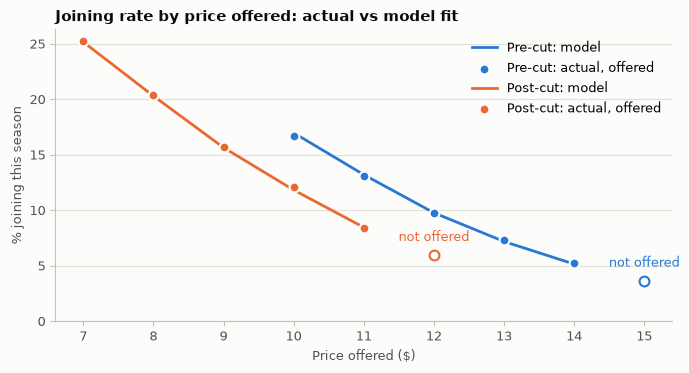

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for (flag, name), color in zip([(0, 'Pre-cut'), (1, 'Post-cut')], [BLUE, ORANGE]):
    offers, base = cal.loc[(flag, 1)], cal.loc[(flag, 0)]
    ax.plot(offers.index, 100 * offers['predicted'], color=color, lw=2, label=f'{name}: model')
    ax.scatter(offers.index, 100 * offers['actual'], s=50, color=color, edgecolor='white', linewidth=1.5,
               zorder=3, label=f'{name}: actual, offered')
    ax.scatter(base.index, 100 * base['actual'], s=50, facecolor='white', edgecolor=color, linewidth=1.5, zorder=3)
    ax.annotate('not offered', (base.index[0], 100 * base['actual'].iloc[0]), xytext=(0, 10),
                textcoords='offset points', ha='center', color=color, fontsize=9)
ax.set_xticks(range(7, 16))
ax.set_ylim(0, None)
ax.set_xlabel('Price offered ($)')
ax.set_ylabel('% joining this season')
ax.set_title('Joining rate by price offered: actual vs model fit', loc='left')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 7. What goes into the tool

The tool does not forecast ad exposure. The user chooses a past season as the ad environment, and the tool applies a base price and discount depth to that season's prospects, keeping who was offered and how much advertising each prospect saw.

In [13]:
# 7.1 Prospect cells: how many prospects each season had at each exposure level. This is all the tool needs.
cells = (d.groupby(['t', 'region_name', 'offer', 'pod', 'soc']).size().rename('prospects').reset_index())
cells.insert(1, 'season', cells['t'].map(u.period_label))


def simulate(model, cells, season, base_price, depth):
    """Joining and first-season revenue if `season`'s prospects faced `base_price`, with `depth` $ off for the offered.

    Keeps that season's prospects, who was offered, and their ad exposure. Prices must stay within $7-$15.
    """
    x = cells[cells['season'].eq(season)].copy()
    x['price'] = base_price - depth * x['offer']
    if not x['price'].between(7, 15).all():
        raise ValueError('Prices outside $7-$15 were never observed; the model is not valid there.')
    p = model.predict(add_terms(x))
    n = x['prospects']
    offered = x['offer'].eq(1)
    return {'season': season, 'base_price': base_price, 'depth': depth,
            'join_rate_offered': (p * n)[offered].sum() / n[offered].sum(),
            'join_rate_not_offered': (p * n)[~offered].sum() / n[~offered].sum(),
            'joiners': (p * n).sum(), 'revenue': (p * n * x['price']).sum()}


# 7.2 Check: at the prices actually charged, the scenario matches what happened in each season
rows = []
for k in seasons:
    g = d[d['t'].eq(k)]
    base = g.loc[g['offer'].eq(0), 'price'].iloc[0]
    run = simulate(final, cells, u.period_label(k), base, 3)
    rows.append({'season': u.period_label(k), 'base_price': base,
                 'not offered: actual': g.loc[g['offer'].eq(0), 'joined'].mean(),
                 'not offered: scenario': run['join_rate_not_offered'],
                 '$3 off: actual': g.loc[g['depth'].eq(3), 'joined'].mean(),
                 '$3 off: scenario': run['join_rate_offered']})
check = pd.DataFrame(rows).set_index('season')
check.iloc[:, 1:] *= 100
display(check.round(1))

# 7.3 Example: three ad environments, base $12 vs $15, each discount depth
exposure_by_season = d.groupby('t')['pod_soc'].mean().sort_values()
picks = {'low ad exposure': exposure_by_season.index[0],
         'typical': exposure_by_season.index[len(exposure_by_season) // 2],
         'high ad exposure': exposure_by_season.index[-1]}
runs = pd.DataFrame([{'environment': f'{name} ({u.period_label(k)})', **simulate(final, cells, u.period_label(k), b, dep)}
                     for name, k in picks.items() for b in (15, 12) for dep in range(0, 6) if b - dep >= 7])
display((100 * runs.pivot_table(index=['environment', 'base_price'], columns='depth', values='join_rate_offered',
                                sort=False)).round(1).rename_axis(columns='% of offered joining, by $ off'))
(runs.pivot_table(index=['environment', 'base_price'], columns='depth', values='revenue', sort=False) / 1000
 ).round(0).rename_axis(columns='first-season revenue ($k), by $ off')

,base_price,not offered: actual,not offered: scenario,$3 off: actual,$3 off: scenario
season,,,,,
Fall 2017,15,1.7,1.7,8.3,8.6
Win 2018,15,2.5,2.6,9.9,10.1
Spr 2018,15,0.1,0.1,2.6,2.5
Sum 2018,15,9.9,9.8,17.4,17.7
Fall 2018,15,0.9,0.9,6.2,6.3
Win 2019,15,6.8,6.9,13.7,13.8
Spr 2019,12,1.8,1.8,11.6,11.3
Sum 2019,12,5.3,5.2,15.7,16.1
Fall 2019,12,11.2,11.2,20.1,20.0


% of offered joining, by $ off             0     1     2     3     4     5
environment                 base_price                                    
low ad exposure (Spr 2019)  15           0.1   0.3   0.7   1.8   3.7   6.9
                            12           1.8   3.7   6.9  11.3  16.5  22.0
typical (Fall 2017)         15           1.6   3.3   5.6   8.6  12.3  16.6
                            12           8.6  12.3  16.6  21.5  26.7  31.8
high ad exposure (Sum 2018) 15           9.6  12.0  14.7  17.7  20.9  24.5
                            12          17.7  20.9  24.5  28.5  32.7  37.0

first-season revenue ($k), by $ off         0      1      2      3      4  \
environment                 base_price                                      
low ad exposure (Spr 2019)  15            3.0    5.0    9.0   17.0   31.0   
                            12           59.0   72.0   92.0  114.0  135.0   
typical (Fall 2017)         15           80.0   98.0  120.0  145.0  171.0   
                            12          337.0  363.0  389.0  411.0  427.0   
high ad exposure (Sum 2018) 15          474.0  494.0  513.0  529.0  544.0   
                            12          694.0  709.0  721.0  730.0  734.0   

first-season revenue ($k), by $ off         5  
environment                 base_price         
low ad exposure (Spr 2019)  15           50.0  
                            12          150.0  
typical (Fall 2017)         15          196.0  
                            12          435.0  
high ad exposure (Sum 2018) 15          556.0  
                            12          732.0

**Reading**

* **At the prices actually charged, the scenario matches each season** within 0.4 pp, for non-offered prospects and for those offered \$3 off.
* **The ad environment changes what a discount is worth.** At a \$12 base, \$5 off raises offered joining from 1.8% to 22.0% in a low-exposure season and from 17.7% to 37.0% in a high-exposure one.
* **Revenue here is first-season revenue from new joiners only.** It leaves out existing members, who would also pay a lower base price, and retention. Those come from the other parts of the tool.

**The tool uses**

* **the joining model coefficients** (`join_model_params.csv`);
* **prospect cells** (`join_prospect_cells.csv`): for each season, the number of prospects by region, offer status, listens and impressions;
* **a reference season chosen by the user** as the ad environment.

**Caveats**

* The ad environment is an assumption. The tool answers "what would this pricing do in a season like X", not "what will next season be".
* Prices outside \$7–\$15 were never observed, and the tool should refuse them.
* The model is fit on the five cut regions. Applying it to Panem assumes Panem's prospects respond to price the same way.
* Who is offered follows a business rule, and each scenario keeps that season's offered group.
* Exposure predicts joining strongly, but this analysis does not measure the causal effect of advertising, so the tool should not be used to evaluate ad spend.

In [14]:
out = Path('outputs')
out.mkdir(exist_ok=True)
final.params.rename('coefficient').to_csv(out / 'join_model_params.csv')
cells.to_csv(out / 'join_prospect_cells.csv', index=False)
slopes.to_csv(out / 'join_price_slope_by_season.csv')
print(f"{len(cells):,} prospect cells across {cells['season'].nunique()} seasons")

23,475 prospect cells across 9 seasons
